# Шаг 0. Загрузка библиотек

In [29]:
pip install ucimlrepo

Note: you may need to restart the kernel to use updated packages.


In [30]:
import pandas as pd
from datetime import datetime
import matplotlib.pyplot as plt
from ucimlrepo import fetch_ucirepo
from collections import Counter

# Шаг 1. Изучите данные и сформируйте временной ряд

## Пункт 1. Загрузите датасет и изучите его структуру.

По ссылке для загрузки датасета https://archive.ics.uci.edu/dataset/352/online+retail, можно найти следующий код, который его имортирует:

In [31]:
online_retail = fetch_ucirepo(id=352) 

Данные содержат 3 набора: сами данные, метаданные и описание переменных.

In [32]:
online_retail.keys()

dict_keys(['data', 'metadata', 'variables'])

Посмотрим на описание переменных:

In [33]:
# Временно отключим максимальную ширину столбцов, чтобы description выводился полностью
pd.set_option("display.max_colwidth", None)

online_retail.variables

,name,role,type,demographic,description,units,missing_values
0,InvoiceNo,ID,Categorical,None,"a 6-digit integral number uniquely assigned to each transaction. If this code starts with letter 'c', it indicates a cancellation",None,no
1,StockCode,ID,Categorical,None,a 5-digit integral number uniquely assigned to each distinct product,None,no
2,Description,Feature,Categorical,None,product name,None,no
3,Quantity,Feature,Integer,None,the quantities of each product (item) per transaction,None,no
4,InvoiceDate,Feature,Date,None,the day and time when each transaction was generated,None,no
5,UnitPrice,Feature,Continuous,None,product price per unit,sterling,no
6,CustomerID,Feature,Categorical,None,a 5-digit integral number uniquely assigned to each customer,None,no
7,Country,Feature,Categorical,None,the name of the country where each customer resides,None,no


In [34]:
pd.reset_option("display.max_colwidth")

Посмотрим на сами данные:

In [35]:
online_retail.data

{'ids':        InvoiceNo StockCode
 0         536365    85123A
 1         536365     71053
 2         536365    84406B
 3         536365    84029G
 4         536365    84029E
 ...          ...       ...
 541904    581587     22613
 541905    581587     22899
 541906    581587     23254
 541907    581587     23255
 541908    581587     22138
 
 [541909 rows x 2 columns],
 'features':                                 Description  Quantity      InvoiceDate  \
 0        WHITE HANGING HEART T-LIGHT HOLDER         6   12/1/2010 8:26   
 1                       WHITE METAL LANTERN         6   12/1/2010 8:26   
 2            CREAM CUPID HEARTS COAT HANGER         8   12/1/2010 8:26   
 3       KNITTED UNION FLAG HOT WATER BOTTLE         6   12/1/2010 8:26   
 4            RED WOOLLY HOTTIE WHITE HEART.         6   12/1/2010 8:26   
 ...                                     ...       ...              ...   
 541904          PACK OF 20 SPACEBOY NAPKINS        12  12/9/2011 12:50   
 541905        

Судя по всему original = ids + features, поэтому посмотрим на originals.

In [36]:
online_retail.data.original

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/2010 8:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12/1/2010 8:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
...,...,...,...,...,...,...,...,...
541904,581587,22613,PACK OF 20 SPACEBOY NAPKINS,12,12/9/2011 12:50,0.85,12680.0,France
541905,581587,22899,CHILDREN'S APRON DOLLY GIRL,6,12/9/2011 12:50,2.10,12680.0,France
541906,581587,23254,CHILDRENS CUTLERY DOLLY GIRL,4,12/9/2011 12:50,4.15,12680.0,France
541907,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,12/9/2011 12:50,4.15,12680.0,France


# RetailDataset

In [37]:
class RetailDataset:
    def __init__(self, online_retail):
        self.df = online_retail
        self.df["InvoiceDate"] = pd.to_datetime(self.df["InvoiceDate"])
        
    def get_most_popular_product_codes(self, count):
        return self.df['StockCode'].value_counts().head(count)

    def describe(self, column_name):
        return self.df[column_name].describe()

    def set_selected_code(self, code):
        self.selected_code = code

    def filter_selected_code(self):
        return self.df[self.df['StockCode'] == self.selected_code]

    def get_all_descriptions_for_selected_code(self):
        return self.filter_selected_code()['Description'].value_counts()

    # def aggregate_quantity_by(self, aggregation):
    #     select_code = self.df['StockCode'] == self.selected_code
    #     exclude_cancellation = ~self.df['InvoiceNo'].astype('str').str.startswith('C')
    #     mask = select_code & exclude_cancellation
    #     return self.df[mask].set_index('InvoiceDate')[['Quantity']].resample(aggregation).sum()

    def missing_data(self, aggregation):
        aggregated = self.aggregate_quantity_by(aggregation)

        all_dates = pd.date_range(
            start=aggregated.index.min(),
            end=aggregated.index.max(),
            freq=aggregation
        )

        # Даты, которых нет в индексе
        missing_dates = all_dates.difference(aggregated.index)
        
        print("Количество пропущенных дат:", len(missing_dates))
        print(missing_dates)

        zero_dates = aggregated[aggregated["Quantity"].eq(0)]

        print("Количество дней с Quantity = 0:", len(zero_dates))
        print(zero_dates)

        nan_rows = aggregated[aggregated["Quantity"].isna()]
        print("Количество NaN:", len(nan_rows))
        print(nan_rows)

    def _agg_text(self, aggregation):
        return 'дням' if aggregation == 'D' else 'неделям' if aggregation == 'W' else 'месяцам' 

    def draw_data(self, aggregation):
        sales = self.aggregate_quantity_by(aggregation)
        plt.figure(figsize=(25,5))
        plt.plot(sales.index, sales['Quantity'])
        plt.xticks(sales.index[::5], rotation=90)
        plt.title(f"Количество продаж по {self._agg_text(aggregation)}")
        plt.xlabel("Дата")
        plt.ylabel("Количество продаж")
        plt.show()


    def draw_missing_data(self, aggregation):
        sales = self.aggregate_quantity_by(aggregation, 1)
        plt.figure(figsize=(25,5))
        plt.plot(sales.index, sales['Quantity'].fillna(0))
        empty_quantity_mask = (sales['Quantity'] == 0) | (sales['Quantity'].isna())
        plt.scatter(sales[empty_quantity_mask].index, sales[empty_quantity_mask]['Quantity'].fillna(0), color='red')
        plt.xticks(sales.index[::5], rotation=90)
        plt.title(f"Количество продаж по {self._agg_text(aggregation)}")
        plt.xlabel("Дата")
        plt.ylabel("Количество продаж")
        plt.show()

    def draw_missing_hist(self):
        sales = self.aggregate_quantity_by('D', 1)
        empty_quantity_mask = (sales['Quantity'] == 0) | (sales['Quantity'].isna())
        dates = pd.to_datetime(sales[empty_quantity_mask].index)
    
        days_ru = ["Понедельник", "Вторник", "Среда", "Четверг", "Пятница", "Суббота", "Воскресенье"]
        
        counts = Counter(dates.weekday)
        
        plt.bar(days_ru, [counts[i] for i in range(7)])
        plt.xlabel("День недели")
        plt.ylabel("Количество")
        plt.title("Количество отсутствующих значений по дням недели")
        plt.xticks(rotation=30, ha="right")
        plt.tight_layout()
        plt.show()

    def draw_sales_by_weekday(self):
        sales = self.aggregate_quantity_by('D')
        s = sales["Quantity"]

        df_weekly = s.rename("sales").to_frame()
        df_weekly["weekday"] = df_weekly.index.dayofweek
        df_weekly["week_start"] = (
            df_weekly.index
            - pd.to_timedelta(df_weekly.index.dayofweek, unit="D")
        )
        
        # Превращаем данные в таблицу:
        # строки — недели, столбцы — дни недели
        weekly_pivot = df_weekly.pivot_table(
            index="week_start",
            columns="weekday",
            values="sales",
            aggfunc="sum"
        )
        
        # Сохраняем правильный порядок дней
        days = ["Пн", "Вт", "Ср", "Чт", "Пт", "Сб", "Вс"]
        weekly_pivot = weekly_pivot.reindex(columns=range(7))
        weekly_pivot.columns = days
        
        # Строим наслоенный график
        plt.figure(figsize=(14, 6))
        
        for week, row in weekly_pivot.iterrows():
            plt.plot(
                days,
                row.values,
                alpha=0.25,
                linewidth=1
            )
        
        plt.xlabel("День недели")
        plt.ylabel("Количество проданных единиц")
        plt.title("Наслоенный график продаж по дням неделям")
        plt.grid(alpha=0.3)
        plt.tight_layout()
        plt.show()


#####

    def aggregate_quantity_by(self, aggregation, min_count = 0):
        select_code = self.df["StockCode"].eq(self.selected_code)
        exclude_cancellation = ~self.df["InvoiceNo"].astype(str).str.startswith("C")
        data = self.df.loc[select_code & exclude_cancellation]

        # min_count=1 сохраняет NaN, если в интервале не было записей
        return (
            data.set_index("InvoiceDate")["Quantity"]
                .resample(aggregation)
                .sum(min_count=min_count)
                .to_frame()
        )

    def diagnose_missing_data(self, aggregation):
        series = self.aggregate_quantity_by(aggregation)
        missing = series["Quantity"].isna()

        print(f"Интервалов без записей: {missing.sum()}")
        print("Их даты:")
        print(series.index[missing].tolist())

        zero = series["Quantity"].eq(0)
        print(f"\nИнтервалов с суммарным Quantity = 0: {zero.sum()}")
        print(series.loc[zero])

        return series

    def detect_iqr_outliers(self, aggregation):
        series = self.aggregate_quantity_by(aggregation)["Quantity"].dropna()

        q1 = series.quantile(0.25)
        q3 = series.quantile(0.75)
        iqr = q3 - q1
        lower = q1 - 1.5 * iqr
        upper = q3 + 1.5 * iqr

        outliers = series[(series < lower) | (series > upper)]

        print(f"Границы по IQR: [{lower:.2f}, {upper:.2f}]")
        print(f"Потенциальных выбросов: {len(outliers)}")
        print(outliers)

        return outliers

    def plot_series(self, aggregation, outliers=None):
        series = self.aggregate_quantity_by(aggregation)["Quantity"]

        plt.figure(figsize=(16, 5))
        plt.plot(series.index, series, linewidth=1, label="Количество")
        plt.axhline(0, color="gray", linewidth=0.8)

        if outliers is not None and not outliers.empty:
            plt.scatter(
                outliers.index, outliers,
                color="red", label="Потенциальные выбросы", zorder=3
            )

        plt.title(f"Продажи товара по {self._agg_text(aggregation)}")
        plt.xlabel("Дата")
        plt.ylabel("Количество")
        plt.legend()
        plt.tight_layout()
        plt.show()

    def analyze_sales(self, aggregation="D", plot=True):
        """
        Анализирует временной ряд Quantity для выбранного StockCode.
    
        aggregation: частота агрегации, например "D" (дни),
                     "W" (недели), "MS" (месяцы).
        plot: строить ли график.
        """
        import pandas as pd
        import matplotlib.pyplot as plt
    
        # Агрегированный ряд выбранного товара
        sales = self.aggregate_quantity_by(aggregation)
        quantity = sales["Quantity"].dropna()
    
        if quantity.empty:
            print("Нет данных для анализа выбранного товара.")
            return None
    
        # Описательная статистика
        stats = quantity.describe(
            percentiles=[0.25, 0.5, 0.75, 0.9, 0.95]
        )
    
        # Пропуски, нулевые значения и отрицательные значения
        missing = sales["Quantity"].isna()
        zero = sales["Quantity"].eq(0)
        negative = sales["Quantity"] < 0
    
        # Потенциальные выбросы по правилу 1.5 × IQR
        q1 = quantity.quantile(0.25)
        q3 = quantity.quantile(0.75)
        iqr = q3 - q1
        lower = q1 - 1.5 * iqr
        upper = q3 + 1.5 * iqr
        outliers = quantity[(quantity < lower) | (quantity > upper)]
    
        # Частота периодов в заголовке графика
        period_names = {
            "D": "дням",
            "W": "неделям",
            "MS": "месяцам",
            "M": "месяцам",
        }
        period_name = period_names.get(aggregation, aggregation)
    
        print("Описательные статистики Quantity:")
        print(stats)
        print(f"\nСуммарное количество: {quantity.sum()}")
        print(f"Интервалов без данных (NaN): {missing.sum()}")
        print(f"Интервалов с Quantity = 0: {zero.sum()}")
        print(f"Интервалов с отрицательным Quantity: {negative.sum()}")
        print(f"Границы выбросов по IQR: [{lower:.2f}, {upper:.2f}]")
        print(f"Потенциальных выбросов: {len(outliers)}")
    
        if not outliers.empty:
            print("\nПотенциальные выбросы:")
            print(outliers)
    
        if plot:
            plt.figure(figsize=(16, 5))
            plt.plot(sales.index, sales["Quantity"], linewidth=1, label="Quantity")
            plt.axhline(0, color="gray", linewidth=0.8)
    
            if not outliers.empty:
                plt.scatter(
                    outliers.index,
                    outliers,
                    color="red",
                    label="Потенциальные выбросы",
                    zorder=3,
                )
    
            plt.title(f"Количество товара по {period_name}")
            plt.xlabel("Дата")
            plt.ylabel("Количество")
            plt.legend()
            plt.tight_layout()
            plt.show()
    
        return {
            "sales": sales,
            "statistics": stats,
            "missing_periods": sales.index[missing],
            "zero_periods": sales.index[zero],
            "negative_periods": sales.index[negative],
            "iqr_bounds": (lower, upper),
            "outliers": outliers,
        }


In [38]:
retail_dataset = RetailDataset(online_retail.data.original)

По каким-то причинам количество товара может быть отрицательным:

In [39]:
retail_dataset.describe('Quantity')

count    541909.000000
mean          9.552250
std         218.081158
min      -80995.000000
25%           1.000000
50%           3.000000
75%          10.000000
max       80995.000000
Name: Quantity, dtype: float64

Давайте проверим, что отрицательное количество только у чеков отмены:

In [40]:
def all_cancellation_invoces_have_neg_quantities(retail_dataset):
    cancellation_invoices_mask = retail_dataset.df['InvoiceNo'].str.startswith('C')
    return retail_dataset.df[cancellation_invoices_mask]['Quantity'].lt(0).all()

def all_negative_quantities_have_cancellation_invoice(retail_dataset):
    negative_quantity_mask = retail_dataset.df['Quantity'] < 0
    return retail_dataset.df[negative_quantity_mask]['InvoiceNo'].str.startswith('C').all()

print('Все операции отмены имеют отрицательный Quantity: ', all_cancellation_invoces_have_neg_quantities(retail_dataset))
print('Все операции с отрицательным Quantity это операции отмены: ', all_negative_quantities_have_cancellation_invoice(retail_dataset))

Все операции отмены имеют отрицательный Quantity:  True
Все операции с отрицательным Quantity это операции отмены:  False


Судя по всему нет. Но давайте тогда разберемся с этим в другом пункте.

## Пункт 2. Определите, какие поля необходимы для отбора товара, даты и показателя продаж.

Если имеются ввиду столбцы, то будем ориентироваться на **StockCode** как на код товара, **InvoiceDate** как на дату продажи, **UnitPrice** как на цену.

## Пункт 3. Выберите товар, который не рассматривался на занятии.

На занятии мы рассматривали товар с кодом **85123A**, его пропустим и посмотрим какие ещё есть популярные товары, чтобы у нас было достаточно данных.

In [41]:
retail_dataset.get_most_popular_product_codes(40)

StockCode
85123A    2313
22423     2203
85099B    2159
47566     1727
20725     1639
84879     1502
22720     1477
22197     1476
21212     1385
20727     1350
22383     1348
22457     1280
23203     1267
POST      1256
22386     1251
22469     1239
22960     1229
21931     1214
22086     1210
22411     1202
20728     1197
22382     1192
22961     1182
22666     1180
23298     1179
22699     1138
22384     1137
23209     1135
82482     1129
22993     1111
22727     1107
22697     1085
23206     1084
22178     1072
20724     1068
23084     1067
20726     1061
22726     1026
21080     1015
23199     1009
Name: count, dtype: int64

Я решил выбрать 20725.

In [42]:
selected_code = "20725"
retail_dataset.set_selected_code(selected_code)

## Пункт 4. Определите показатель продаж и агрегируйте данные по дням, неделям и месяцам. Необходимо рассмотреть все варианты агрегации.

У выбранного продукта есть два описания. Судя по названию, они могут быть одним и тем же продуктом, поэтому я не буду считать, что это выброс.

In [43]:
retail_dataset.get_all_descriptions_for_selected_code()

Description
LUNCH BAG RED RETROSPOT    1638
LUNCH BAG RED SPOTTY          1
Name: count, dtype: int64

Агрегация по дням:

In [44]:
retail_dataset.aggregate_quantity_by('D')

,Quantity
InvoiceDate,
2010-12-01,78
2010-12-02,11
2010-12-03,93
2010-12-04,0
2010-12-05,36
...,...
2011-12-05,50
2011-12-06,85
2011-12-07,35


Агрегация по неделям:

In [45]:
retail_dataset.aggregate_quantity_by('W')

,Quantity
InvoiceDate,
2010-12-05,218
2010-12-12,283
2010-12-19,187
2010-12-26,44
2011-01-02,0
2011-01-09,462
2011-01-16,642
2011-01-23,128
2011-01-30,171


Агрегация по месяцам:

In [46]:
retail_dataset.aggregate_quantity_by('ME')

,Quantity
InvoiceDate,
2010-12-31,732
2011-01-31,1588
2011-02-28,1158
2011-03-31,1505
2011-04-30,1125
2011-05-31,2355
2011-06-30,1638
2011-07-31,1730
2011-08-31,2154


# Шаг 2. Оцените качество данных

## Пункт 1. Проверьте временной ряд на пропуски и определите их количество и расположение.

Если считать данные по дням, то есть 76 дат, в которых нет данных о продажах.

Количество пропущенных дат: 0
DatetimeIndex([], dtype='datetime64[ns]', freq='D')
Количество дней с Quantity = 0: 76
             Quantity
InvoiceDate          
2010-12-04          0
2010-12-11          0
2010-12-18          0
2010-12-24          0
2010-12-25          0
...               ...
2011-11-05          0
2011-11-12          0
2011-11-19          0
2011-11-26          0
2011-12-03          0

[76 rows x 1 columns]
Количество NaN: 0
Empty DataFrame
Columns: [Quantity]
Index: []


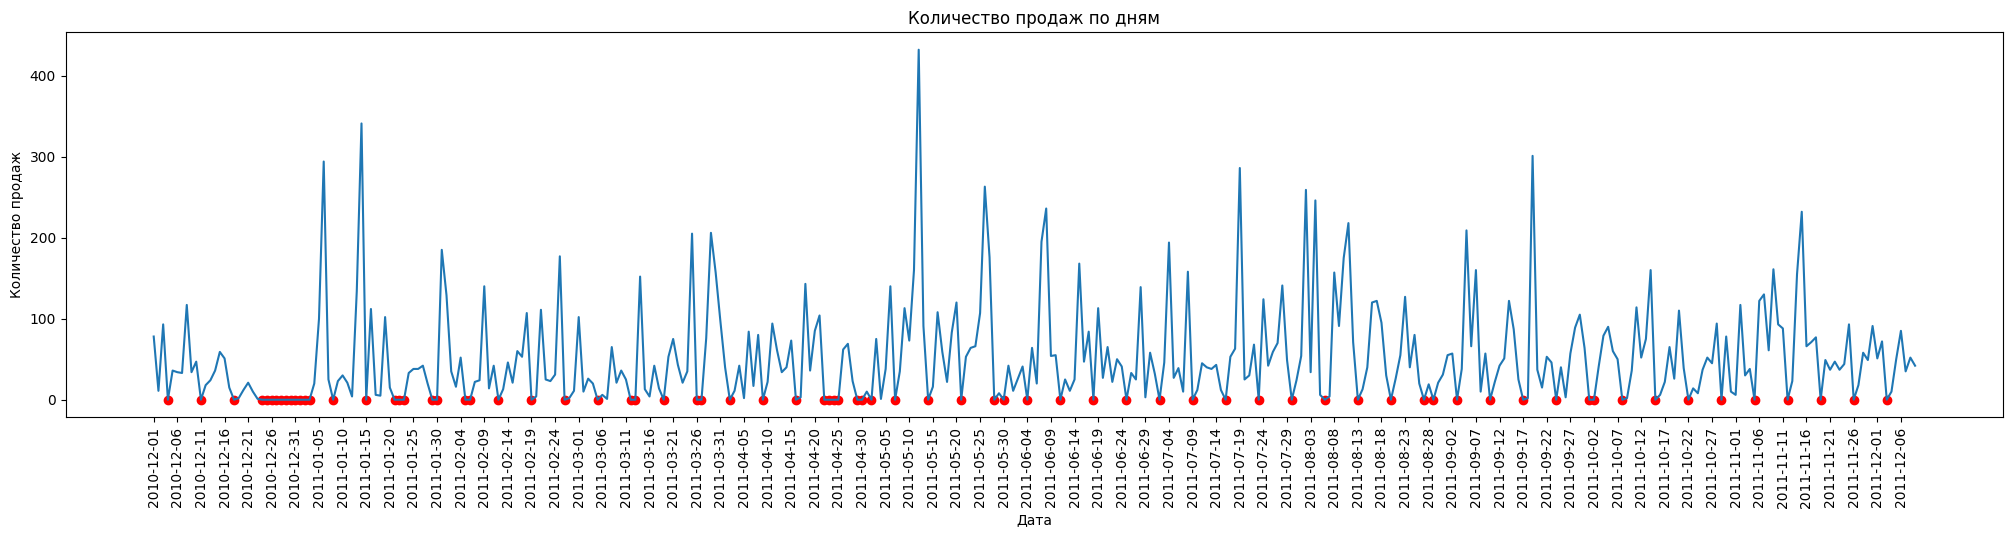

In [47]:
retail_dataset.missing_data('D')
retail_dataset.draw_missing_data('D')

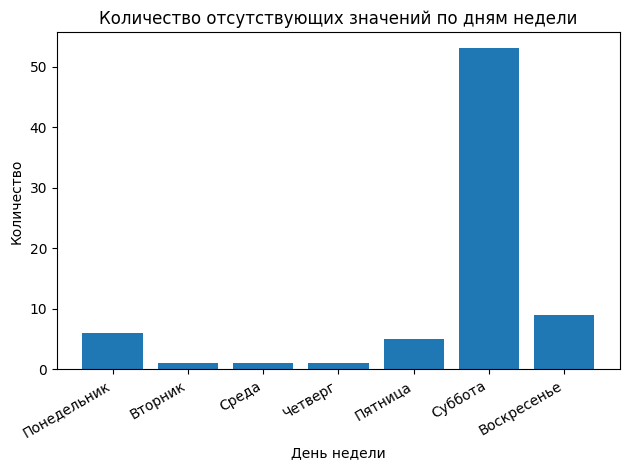

In [48]:
retail_dataset.draw_missing_hist()

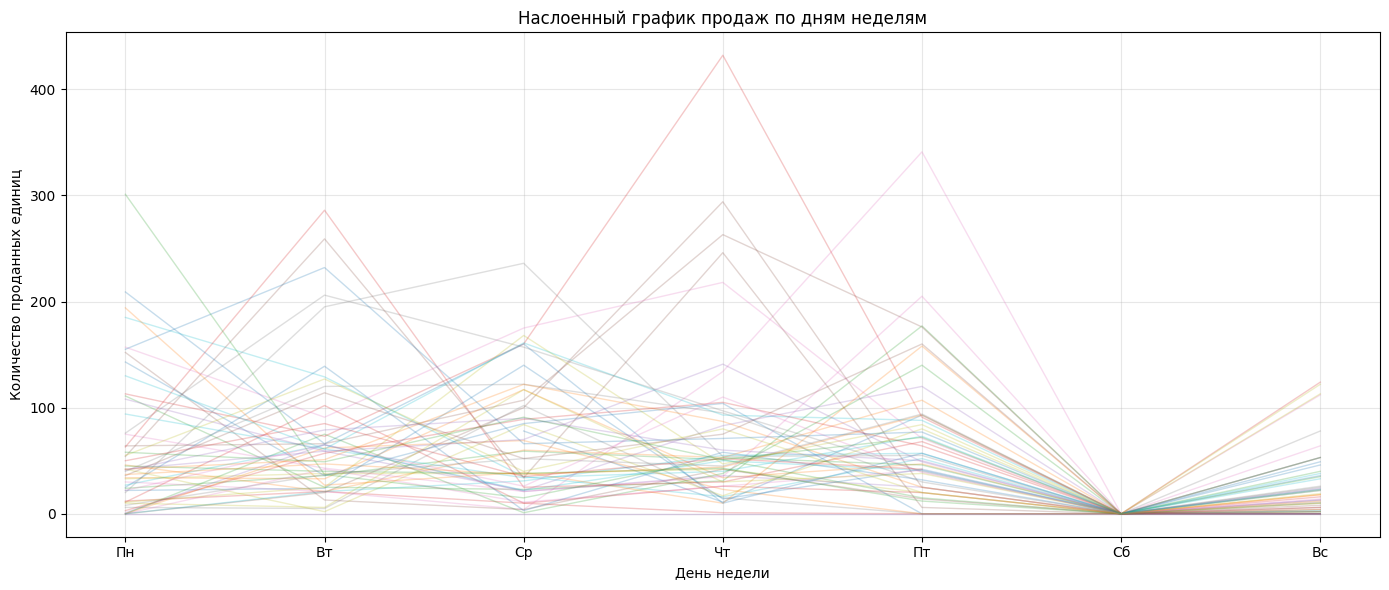

In [49]:
retail_dataset.draw_sales_by_weekday()

Одна неделя, в которой не было продаж.

Количество пропущенных дат: 0
DatetimeIndex([], dtype='datetime64[ns]', freq='W-SUN')
Количество дней с Quantity = 0: 1
             Quantity
InvoiceDate          
2011-01-02          0
Количество NaN: 0
Empty DataFrame
Columns: [Quantity]
Index: []


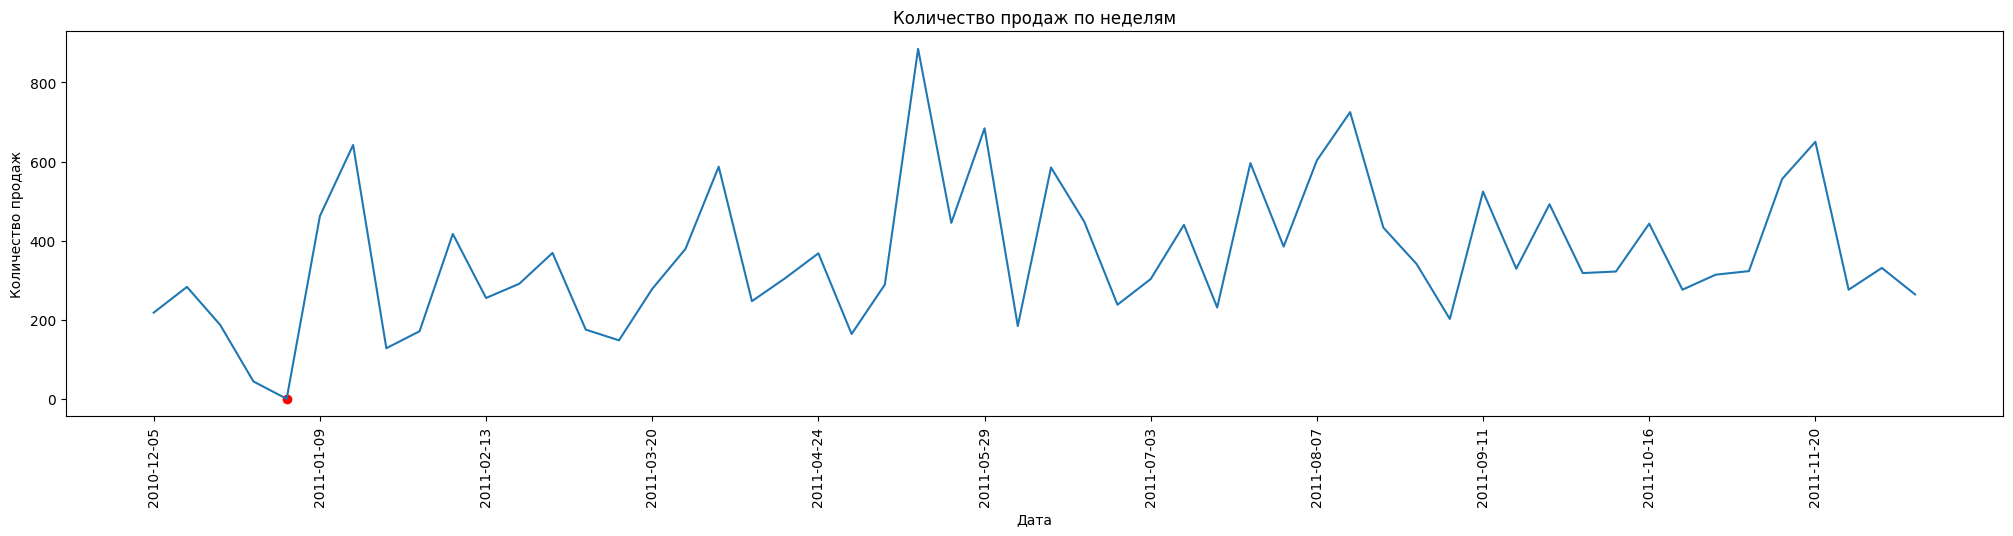

In [50]:
retail_dataset.missing_data('W')
retail_dataset.draw_missing_data('W')

И не было месяца, в котором продажи были бы нулевыми.

Количество пропущенных дат: 0
DatetimeIndex([], dtype='datetime64[ns]', freq='ME')
Количество дней с Quantity = 0: 0
Empty DataFrame
Columns: [Quantity]
Index: []
Количество NaN: 0
Empty DataFrame
Columns: [Quantity]
Index: []


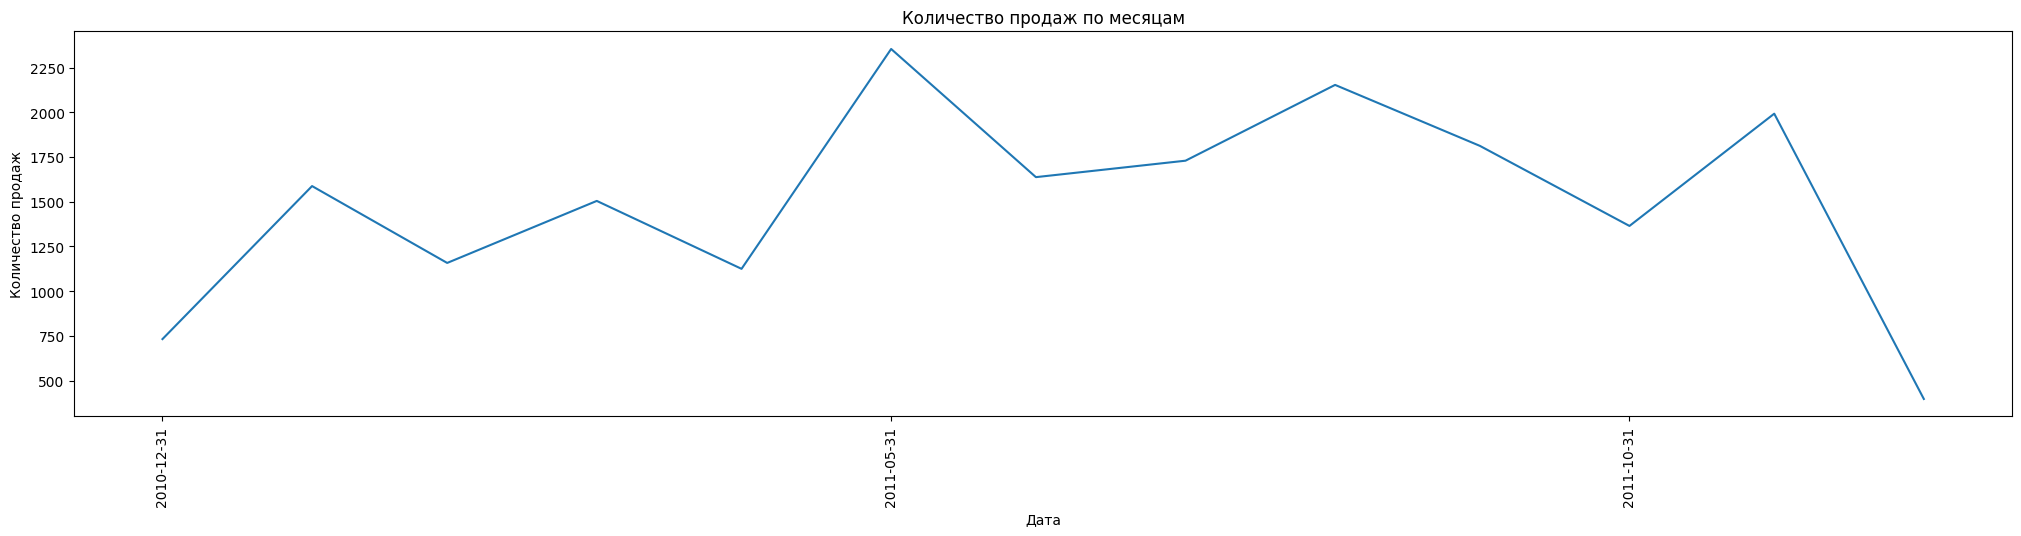

In [51]:
retail_dataset.missing_data('ME')
retail_dataset.draw_missing_data('ME')

## Пункт 2. Выявите потенциальные выбросы подходящим методом.

Здесь я использовал квартильный метод IQR.

Интервалов без записей: 0
Их даты:
[]

Интервалов с суммарным Quantity = 0: 76
             Quantity
InvoiceDate          
2010-12-04          0
2010-12-11          0
2010-12-18          0
2010-12-24          0
2010-12-25          0
...               ...
2011-11-05          0
2011-11-12          0
2011-11-19          0
2011-11-26          0
2011-12-03          0

[76 rows x 1 columns]
Границы по IQR: [-91.50, 168.50]
Потенциальных выбросов: 20
InvoiceDate
2011-01-06    294
2011-01-14    341
2011-01-31    185
2011-02-25    177
2011-03-25    205
2011-03-29    206
2011-05-12    432
2011-05-26    263
2011-05-27    176
2011-06-07    195
2011-06-08    236
2011-07-04    194
2011-07-19    286
2011-08-02    259
2011-08-04    246
2011-08-10    175
2011-08-11    218
2011-09-05    209
2011-09-19    301
2011-11-15    232
Name: Quantity, dtype: int64


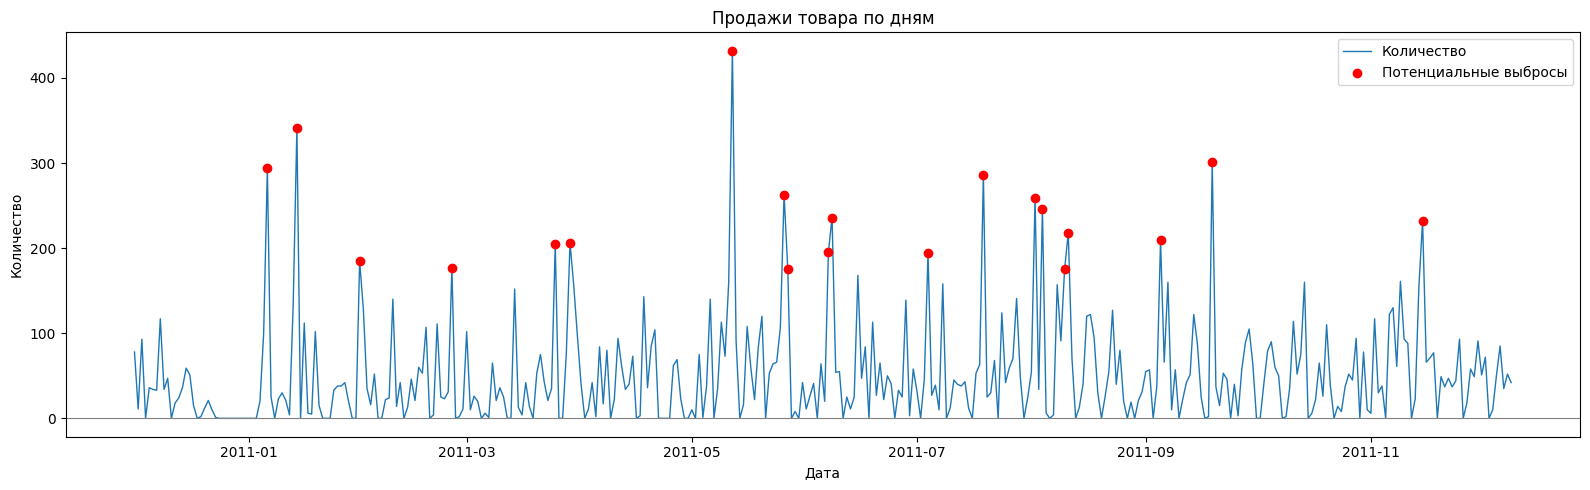

In [52]:
series = retail_dataset.diagnose_missing_data("D")
outliers = retail_dataset.detect_iqr_outliers("D")
retail_dataset.plot_series("D", outliers)


## Пункт 3. Визуализируйте ряд до обработки.

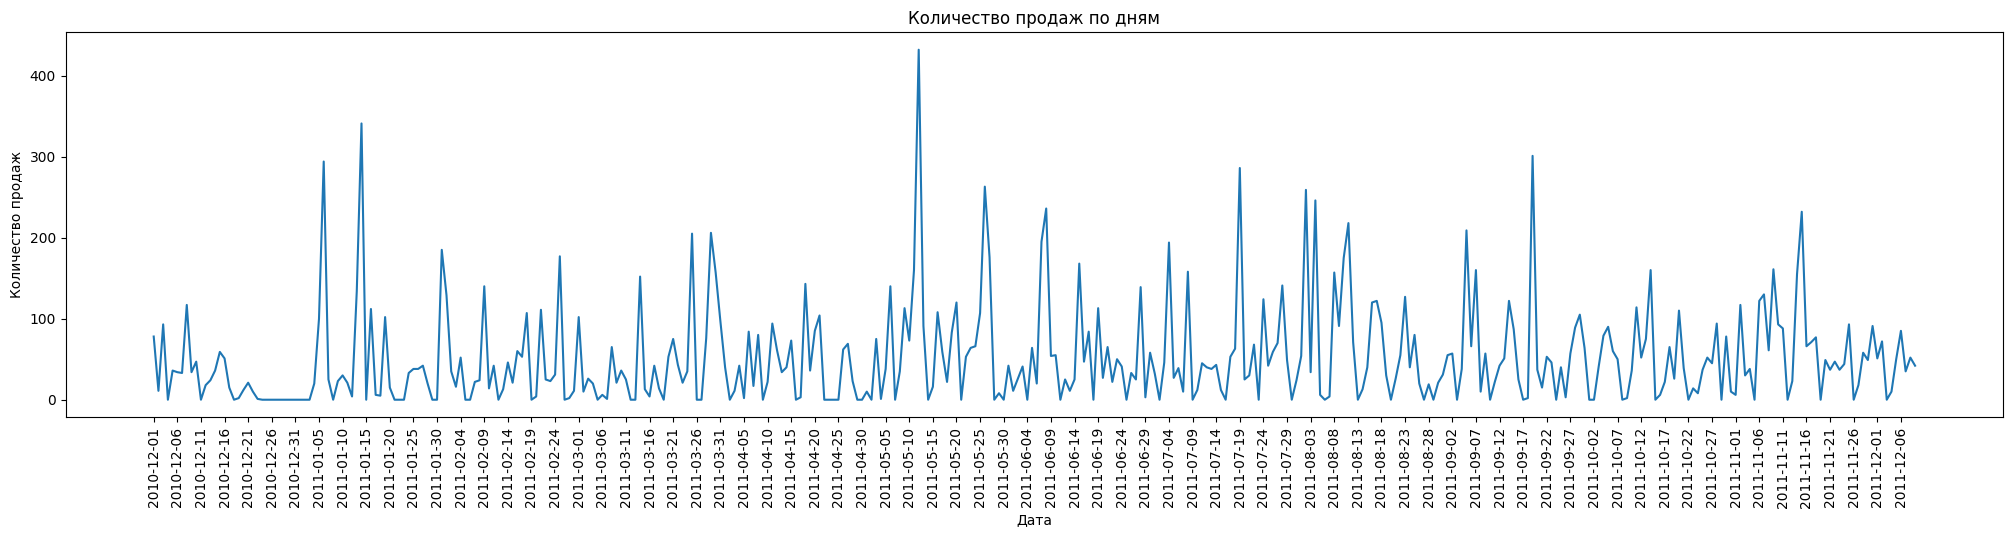

In [53]:
retail_dataset.draw_data('D')

## Пункт 4. Если вы выполняете обработку пропусков или выбросов, обоснуйте выбранный способ и покажите результат.

Мне кажется, что для того, чтобы выполнять обработку данных, нужно понимать конечную цель, алгоритм и что мы вообще будем с данными делать. Для какого-то алгоритма важно, чтобы не было выбросов, например, для линейной регрессии. Для решающих деревьев это не сильно важно. Где-то может быть полезно заполнить каким-нибудь средним значением пропуски, где-то нулём. Поскольку из текста домашнего задания не очень понятно, что и как будет делаться дальше, то я пока не буду ничего удалять и обрабатывать.

# Шаг 3. Проведите визуальный и описательный анализ

## Пункт 1. Постройте график временного ряда.

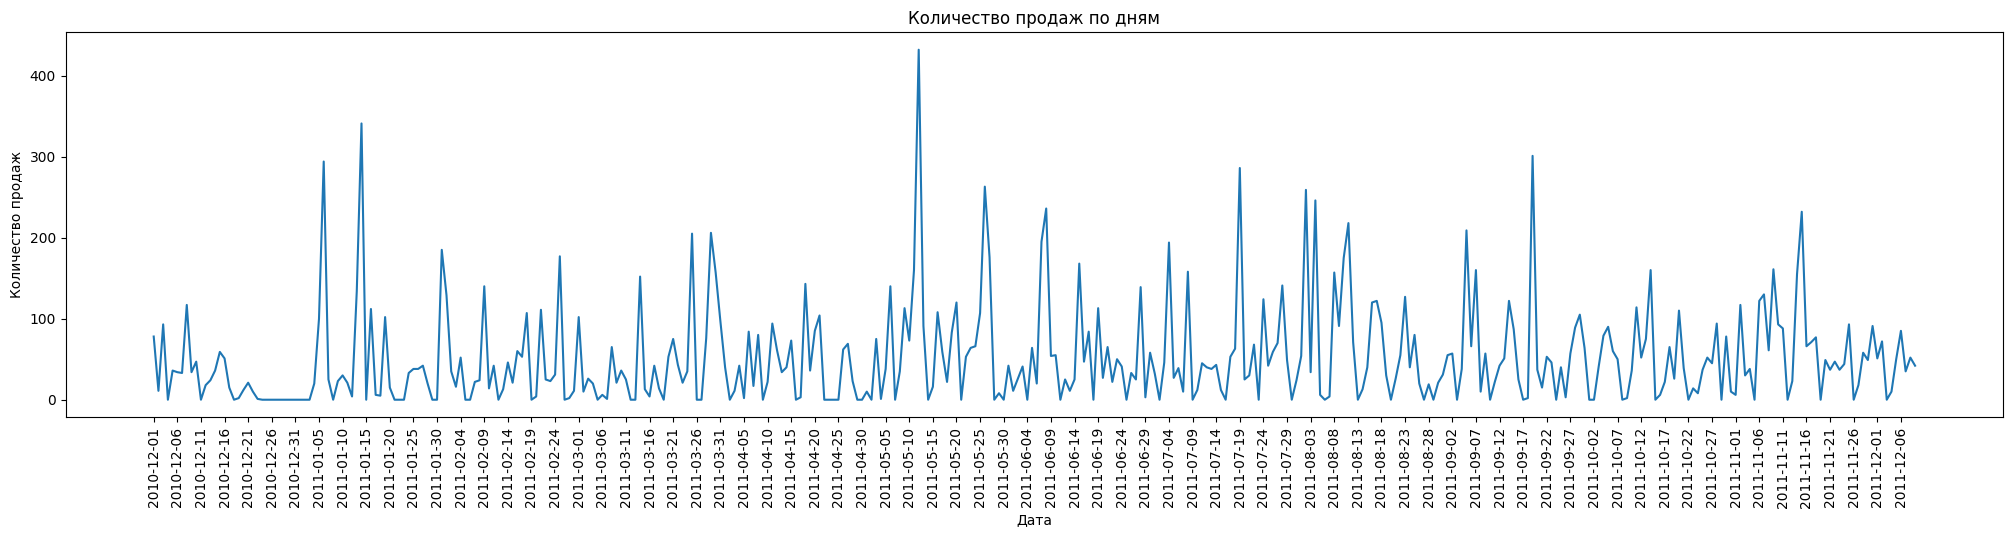

In [54]:
retail_dataset.draw_data('D')

## Пункт 2. Рассчитайте основные описательные статистики и дополнительные характеристики, которые считаете полезными для анализа продаж.

Описательные статистики Quantity:
count     54.000000
mean     362.092593
std      178.255199
min        0.000000
25%      249.000000
50%      322.500000
75%      447.250000
90%      600.900000
95%      661.900000
max      885.000000
Name: Quantity, dtype: float64

Суммарное количество: 19553
Интервалов без данных (NaN): 0
Интервалов с Quantity = 0: 1
Интервалов с отрицательным Quantity: 0
Границы выбросов по IQR: [-48.38, 744.62]
Потенциальных выбросов: 1

Потенциальные выбросы:
InvoiceDate
2011-05-15    885
Freq: W-SUN, Name: Quantity, dtype: int64


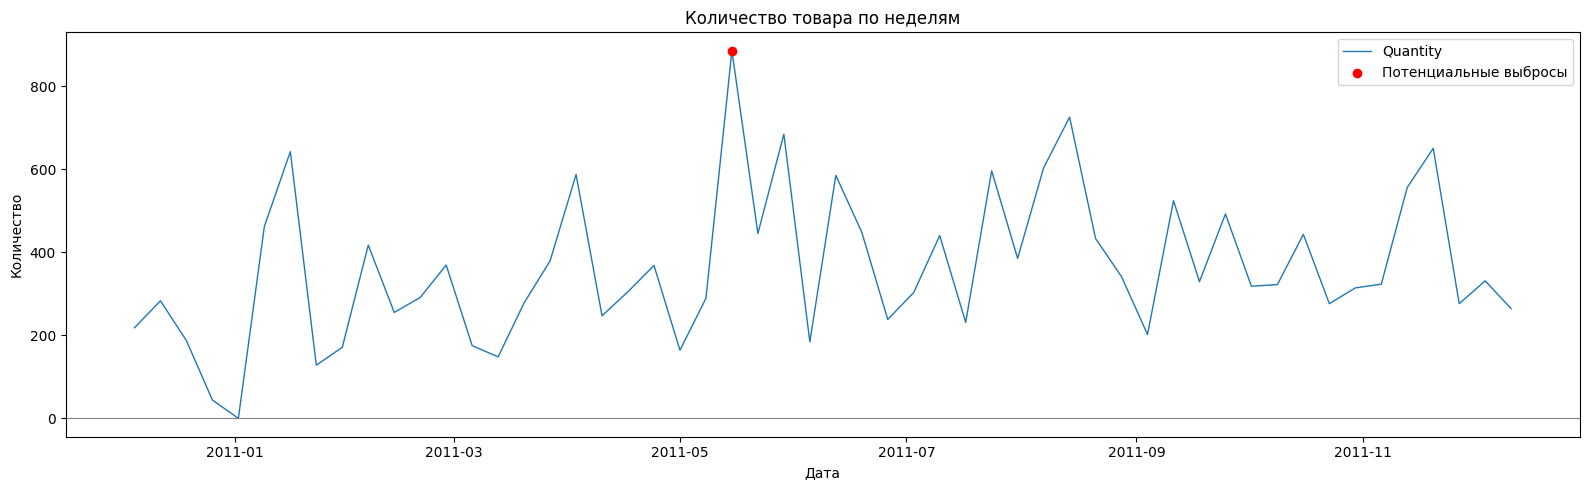

{'sales':              Quantity
 InvoiceDate          
 2010-12-05        218
 2010-12-12        283
 2010-12-19        187
 2010-12-26         44
 2011-01-02          0
 2011-01-09        462
 2011-01-16        642
 2011-01-23        128
 2011-01-30        171
 2011-02-06        417
 2011-02-13        255
 2011-02-20        291
 2011-02-27        369
 2011-03-06        175
 2011-03-13        148
 2011-03-20        278
 2011-03-27        379
 2011-04-03        587
 2011-04-10        247
 2011-04-17        305
 2011-04-24        368
 2011-05-01        164
 2011-05-08        289
 2011-05-15        885
 2011-05-22        445
 2011-05-29        684
 2011-06-05        184
 2011-06-12        585
 2011-06-19        448
 2011-06-26        238
 2011-07-03        303
 2011-07-10        440
 2011-07-17        231
 2011-07-24        596
 2011-07-31        385
 2011-08-07        603
 2011-08-14        725
 2011-08-21        433
 2011-08-28        341
 2011-09-04        202
 2011-09-11        524
 2

In [55]:
retail_dataset.analyze_sales("W")

## Пункт 3. Исследуйте изменение уровня и разброса значений во времени.

Для оценки изменения уровня продаж используем скользящее среднее, а для оценки локального разброса скользящее стандартное отклонение. Для дневного ряда выбрано окно из 7 наблюдений, то есть примерно одна календарная неделя.

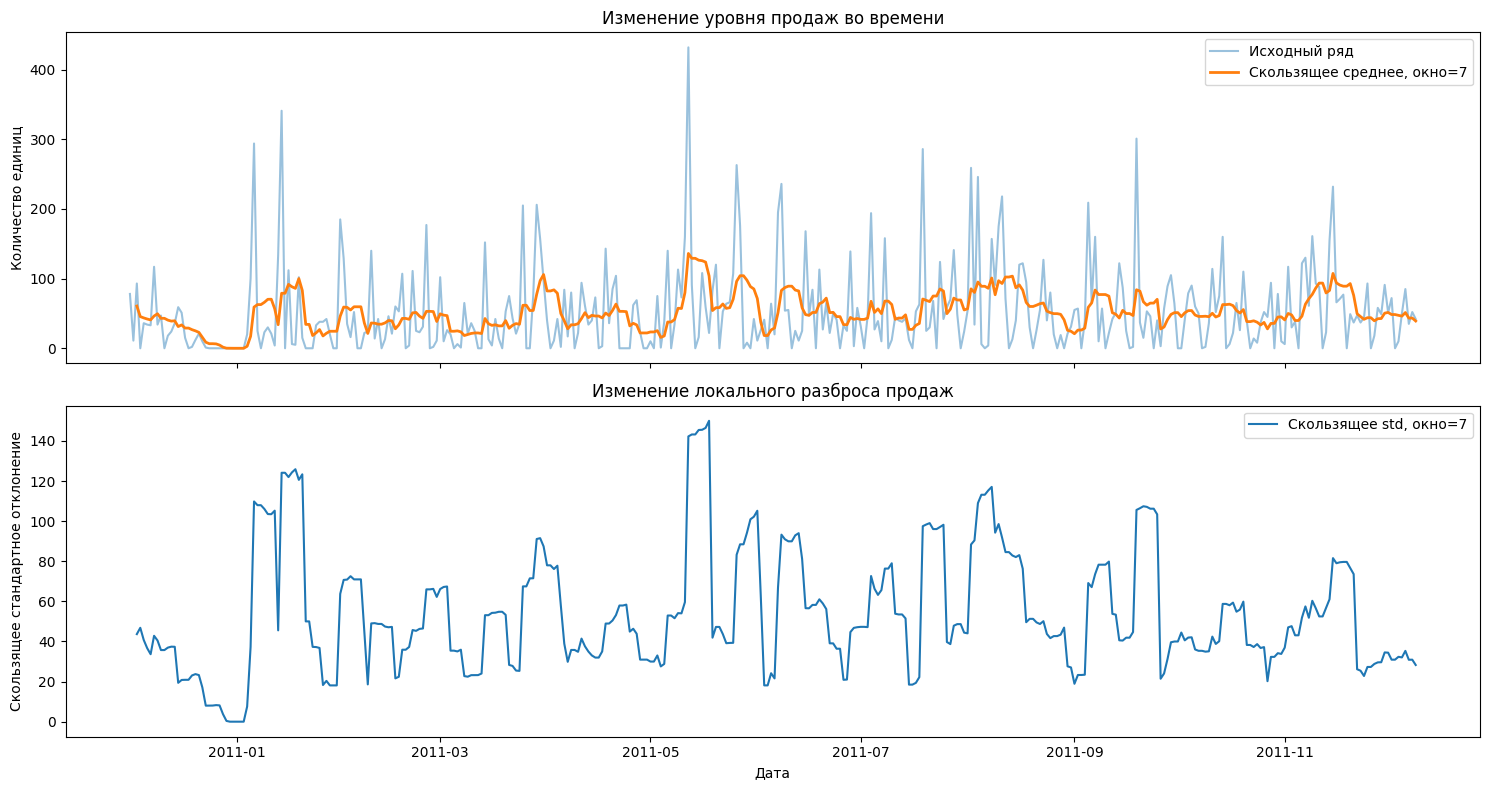

Среднее скользящее среднее: 52.302
Среднее скользящее стандартное отклонение: 54.044


In [66]:
def rolling_diagnostics(retail_dataset, aggregation="D", window=7):
    """Возвращает ряд, скользящее среднее и скользящее стандартное отклонение."""
    series = retail_dataset.aggregate_quantity_by(aggregation)["Quantity"].astype(float)
    min_periods = max(2, window // 2)
    rolling_mean = series.rolling(window=window, min_periods=min_periods).mean()
    rolling_std = series.rolling(window=window, min_periods=min_periods).std()

    fig, axes = plt.subplots(2, 1, figsize=(15, 8), sharex=True)
    axes[0].plot(series.index, series, alpha=0.45, label="Исходный ряд")
    axes[0].plot(rolling_mean.index, rolling_mean, linewidth=2, label=f"Скользящее среднее, окно={window}")
    axes[0].set_title("Изменение уровня продаж во времени")
    axes[0].set_ylabel("Количество единиц")
    axes[0].legend()
    axes[1].plot(rolling_std.index, rolling_std, label=f"Скользящее std, окно={window}")
    axes[1].set_title("Изменение локального разброса продаж")
    axes[1].set_xlabel("Дата")
    axes[1].set_ylabel("Скользящее стандартное отклонение")
    axes[1].legend()
    plt.tight_layout()
    plt.show()

    result = pd.DataFrame({"Quantity": series, "rolling_mean": rolling_mean, "rolling_std": rolling_std})
    print("Среднее скользящее среднее:", round(rolling_mean.mean(), 3))
    print("Среднее скользящее стандартное отклонение:", round(rolling_std.mean(), 3))
    return result

rolling_results = rolling_diagnostics(retail_dataset, aggregation="D", window=7)

По скользящему среднему локальный уровень продаж меняется: в начале года он в целом невысокий, затем становится выше и заметно колеблется примерно с весны до осени. К концу года средний уровень снижается. При этом отдельные резкие всплески на верхнем графике не выглядят устойчивым ростом.

Разброс продаж тоже неодинаков. На нижнем графике видны периоды повышенной изменчивости — особенно около весны и в середине года; между ними разброс временами уменьшается. К концу года он выглядит сравнительно умеренным.

Итого: графики указывают на меняющиеся во времени локальный уровень и разброс продаж, но сами по себе не подтверждают ни устойчивый тренд, ни сезонность.

## Пункт 4. При необходимости используйте дополнительные графики для выявления закономерностей.

Дополнительно построим распределение дневных значений и сравним среднее количество продаж по дням недели. Это помогает увидеть асимметрию распределения, экстремальные значения и возможное повторение недельного профиля.

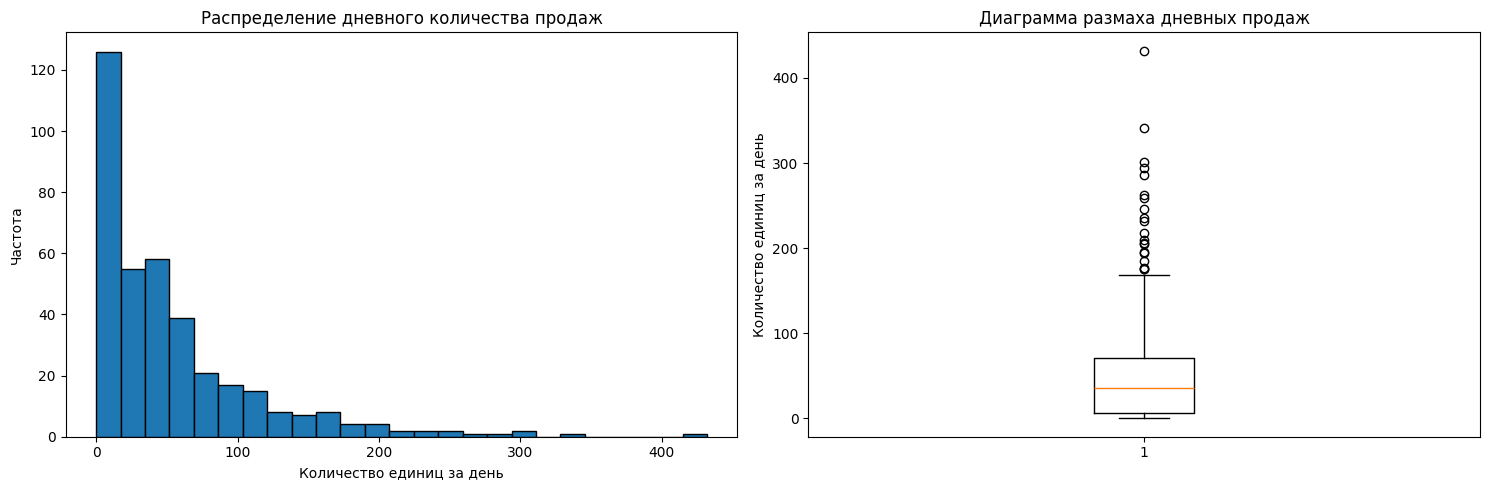

,mean,median,count
Пн,60.698113,41.0,53
Вт,70.150943,57.0,53
Ср,67.925926,52.0,54
Чт,73.537037,50.5,54
Пт,66.148148,49.5,54
Сб,0.000000,0.0,53
Вс,26.547170,16.0,53


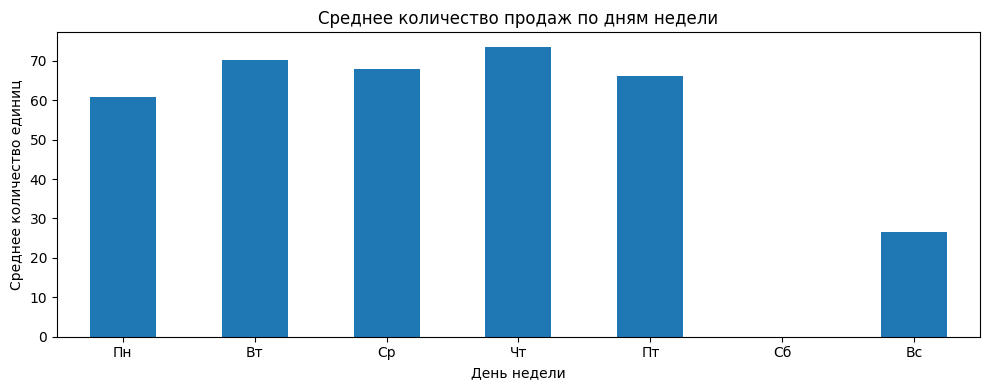

In [57]:
daily_sales = retail_dataset.aggregate_quantity_by("D")["Quantity"].dropna()

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
axes[0].hist(daily_sales, bins=25, edgecolor="black")
axes[0].set_title("Распределение дневного количества продаж")
axes[0].set_xlabel("Количество единиц за день")
axes[0].set_ylabel("Частота")

axes[1].boxplot(daily_sales, vert=True)
axes[1].set_title("Диаграмма размаха дневных продаж")
axes[1].set_ylabel("Количество единиц за день")
plt.tight_layout()
plt.show()

# Среднее и медиана по дням недели (0 — понедельник, 6 — воскресенье)
weekday_profile = daily_sales.groupby(daily_sales.index.dayofweek).agg(["mean", "median", "count"])
weekday_profile.index = ["Пн", "Вт", "Ср", "Чт", "Пт", "Сб", "Вс"]
display(weekday_profile)

weekday_profile["mean"].plot(kind="bar", figsize=(10, 4))
plt.title("Среднее количество продаж по дням недели")
plt.xlabel("День недели")
plt.ylabel("Среднее количество единиц")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

**Интерпретация дополнительных графиков.** Гистограмма показывает форму распределения дневных продаж, а boxplot — медиану, межквартильный размах и потенциально экстремальные наблюдения. Столбчатая диаграмма позволяет сравнить средние продажи по дням недели. Различия могут быть признаком недельного паттерна, но для вывода о сезонности их необходимо сопоставить с декомпозицией и учитывать число наблюдений в каждой группе.

# Шаг 4. Выполните декомпозицию временного ряда

## Пункт 1. Выберите подходящий метод декомпозиции.

Используем `seasonal_decompose` как и в семинаре. Она представляет наблюдение как сумму трендовой, сезонной и остаточной компонент.
Для дневного ряда проверим период 7 — повторение профиля по дням недели. Это гипотеза о недельной сезонности, а не о годовой сезонности. Аддитивная модель выбрана, так как количество продаж может принимать нулевые и отрицательные значения, а мультипликативная модель для таких значений неприменима.

## Пункт 2. Разложите временной ряд на компоненты, предусмотренные выбранным методом.

В результате выполнения функции строятся четыре графика: исходный ряд, тренд, сезонная компонента и остаток. Для аддитивной модели выполняется соотношение: наблюдение = тренд + сезонность + остаток.

/tmp/ipykernel_50/899568460.py:5: FutureWarning: `extrapolate_trend='freq'` is deprecated and will be removed in 0.16, use `extrapolate_trend='period'` instead.
  decomposition = seasonal_decompose(


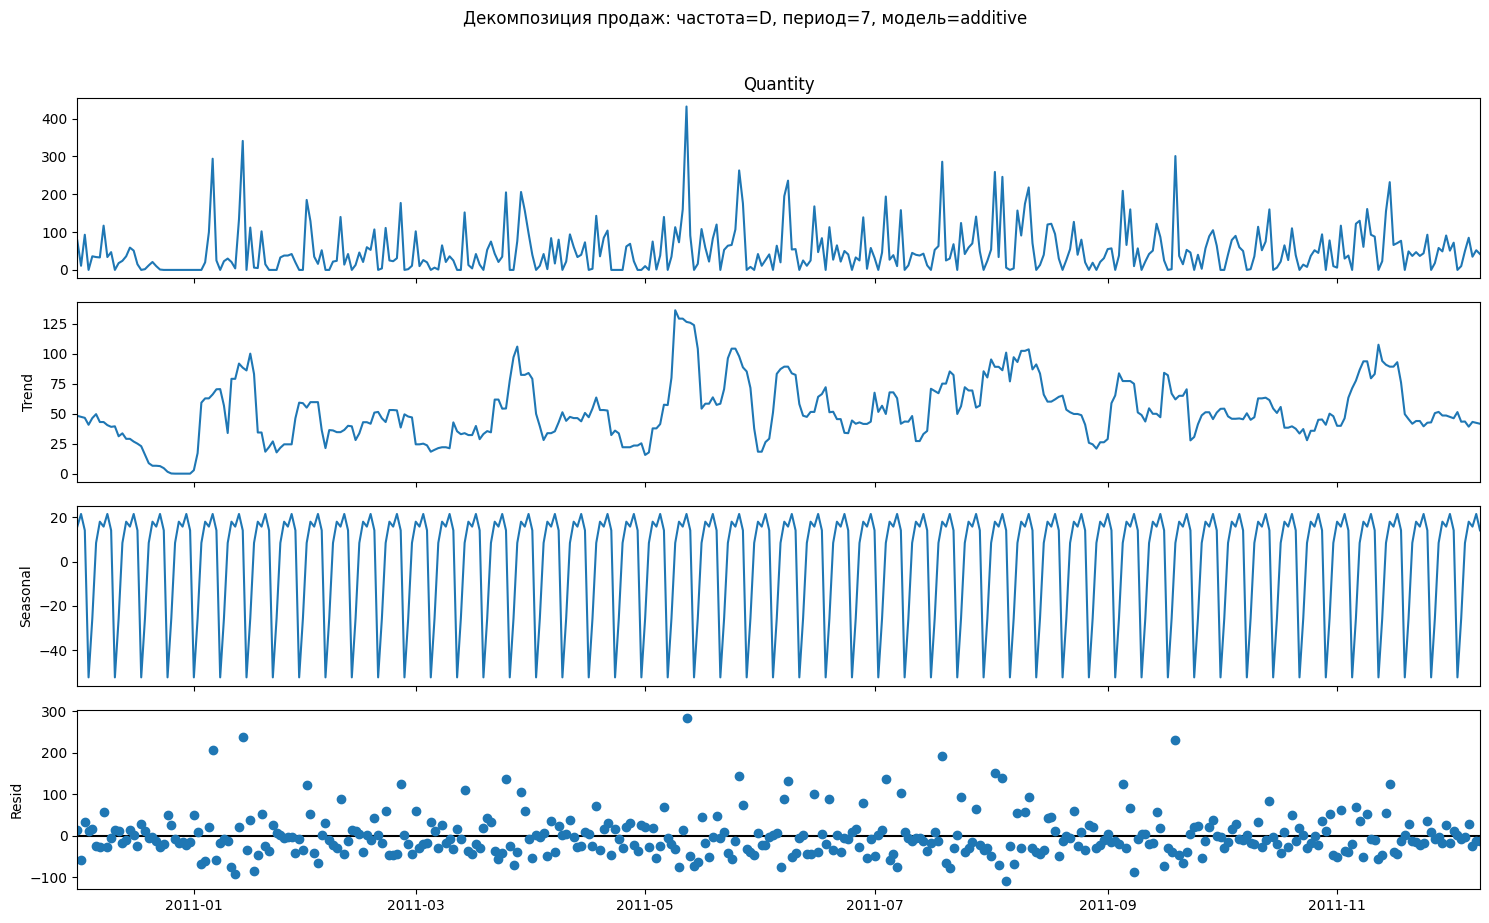

Период сезонности: 7
Дисперсия сезонной компоненты: 669.576
Дисперсия остаточной компоненты: 2593.048
Отношение дисперсии сезонной компоненты к сумме сезонной и остаточной: 0.205


In [71]:
from statsmodels.tsa.seasonal import seasonal_decompose

def decompose_sales_series(retail_dataset, aggregation="D", period=7, model="additive"):
    series = retail_dataset.aggregate_quantity_by(aggregation)["Quantity"].astype(float)
    decomposition = seasonal_decompose(
        series, model=model, period=period, extrapolate_trend="freq"
    )
    fig = decomposition.plot()
    fig.set_size_inches(15, 9)
    fig.suptitle(f"Декомпозиция продаж: частота={aggregation}, период={period}, модель={model}", y=1.02)
    plt.tight_layout()
    plt.show()

    seasonal_var = decomposition.seasonal.var()
    residual_var = decomposition.resid.var()
    denominator = seasonal_var + residual_var
    seasonal_strength = (seasonal_var / denominator) if denominator > 0 else float("nan")
    print("Период сезонности:", period)
    print("Дисперсия сезонной компоненты:", round(seasonal_var, 3))
    print("Дисперсия остаточной компоненты:", round(residual_var, 3))
    print("Отношение дисперсии сезонной компоненты к сумме сезонной и остаточной:", round(seasonal_strength, 3))
    return decomposition, seasonal_strength

decomposition, seasonal_strength = decompose_sales_series(
    retail_dataset, aggregation="D", period=7, model="additive"
)

## Пункт 3. Проанализируйте тренд, сезонную и остаточную составляющие.

Тренд. Среднее значение тренда — около 52,2, стандартное отклонение — 24,8, диапазон — от 0 до 136,1. Это указывает на заметные изменения сглаженного уровня продаж, но по сводной таблице нельзя определить, в какие именно периоды он рос или снижался. Для этого нужен график тренда.

Сезонная компонента. Среднее близко к нулю (0,14), что ожидаемо для компоненты, центрированной относительно тренда. Её стандартное отклонение — 25,9, то есть примерно половина среднего уровня тренда; сезонные колебания поэтому могут быть существенными относительно типичного уровня. Значения лежат от −52,3 до 21,5, причём отрицательные отклонения достигают большей величины. Повторяемость этого недельного профиля следует оценивать по графику сезонной компоненты.

Остатки. Среднее остатка близко к нулю (−0,09), но стандартное отклонение — 50,9, почти вдвое больше, чем у сезонной компоненты. Диапазон широкий: от −109,0 до 284,1. Особенно большой положительный максимум указывает на возможный разовый всплеск, не объяснённый трендом и недельной сезонностью; его причину по одной декомпозиции установить нельзя.

В целом остаточные колебания велики, а сезонная составляющая заметна относительно среднего уровня тренда. Чтобы назвать конкретные периоды изменений и проверить повторяемость недельного профиля, нужны графики декомпозиции.





In [73]:
# Дополнительная сводка по компонентам декомпозиции
components_summary = pd.DataFrame({
    "mean": {
        "trend": decomposition.trend.mean(),
        "seasonal": decomposition.seasonal.mean(),
        "resid": decomposition.resid.mean(),
    },
    "std": {
        "trend": decomposition.trend.std(),
        "seasonal": decomposition.seasonal.std(),
        "resid": decomposition.resid.std(),
    },
    "min": {
        "trend": decomposition.trend.min(),
        "seasonal": decomposition.seasonal.min(),
        "resid": decomposition.resid.min(),
    },
    "max": {
        "trend": decomposition.trend.max(),
        "seasonal": decomposition.seasonal.max(),
        "resid": decomposition.resid.max(),
    },
})
display(components_summary)

,mean,std,min,max
trend,52.229155,24.805309,0.000000,136.142857
seasonal,0.137485,25.876160,-52.269904,21.510116
resid,-0.085891,50.921983,-108.965615,284.061312


## Пункт 4. Сделайте вывод о наличии или отсутствии выраженной сезонности.

По имеющимся числам выраженная недельная сезонность не подтверждена: стандартное отклонение сезонной компоненты (25,9) примерно вдвое меньше разброса остатков (50,9). Это говорит, что необъяснённые сезонностью колебания заметно сильнее.

Для более уверенного вывода нужно также увидеть повторяющийся профиль на сезонном графике и согласованные различия средних продаж по дням недели.

# Шаг 5. Проверьте стационарность

## Пункт 1. Оцените стационарность исходного временного ряда с помощью подходящих методов.

Проверим дневной ряд визуально и с помощью двух статистических тестов: ADF и KPSS. Перед тестированием используем тот же дневной ряд, который был сформирован на шаге 1.

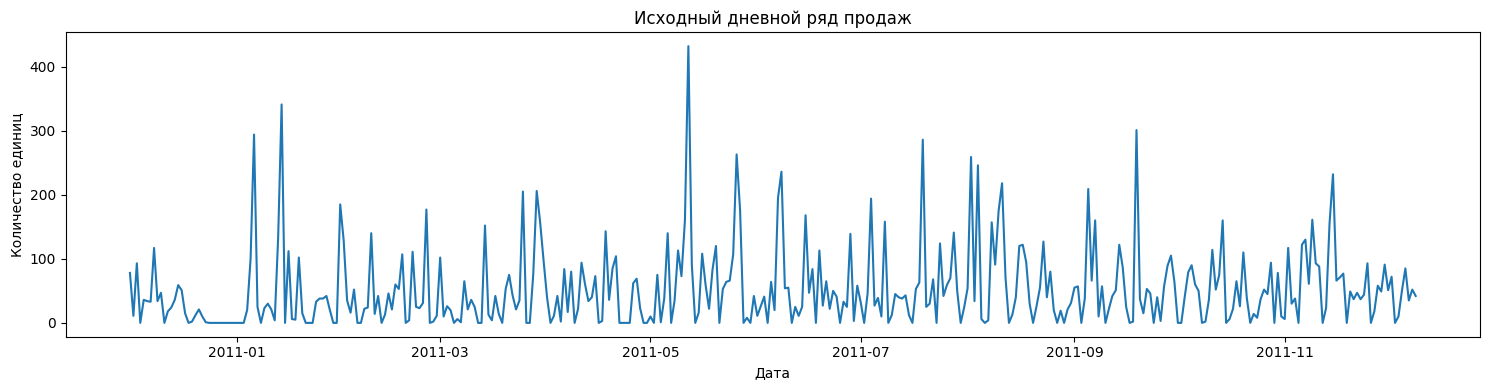

In [60]:
daily_series = retail_dataset.aggregate_quantity_by("D")["Quantity"].astype(float)

plt.figure(figsize=(15, 4))
plt.plot(daily_series.index, daily_series)
plt.title("Исходный дневной ряд продаж")
plt.xlabel("Дата")
plt.ylabel("Количество единиц")
plt.tight_layout()
plt.show()

## Пункт 2. При использовании статистических тестов укажите, какой именно тест применён и как интерпретируется его результат.

- **ADF (Augmented Dickey–Fuller):** нулевая гипотеза — в ряду присутствует единичный корень, то есть ряд нестационарен. При `p-value < 0.05` нулевая гипотеза отвергается.
- **KPSS (Kwiatkowski–Phillips–Schmidt–Shin):** нулевая гипотеза — ряд стационарен вокруг константы. При `p-value < 0.05` нулевая гипотеза отвергается.

In [75]:
from statsmodels.tsa.stattools import adfuller, kpss

def check_stationarity(series, name="Временной ряд"):
    x = pd.Series(series).dropna().astype(float)

    print(f"===== {name} =====")
    adf = adfuller(x, regression="c", autolag="AIC")
    print(f"ADF statistic = {adf[0]:.4f}; p-value = {adf[1]:.6f}")
    print("ADF:", "нулевая гипотеза отвергается — есть свидетельство стационарности" if adf[1] < 0.05
          else "нулевая гипотеза не отвергается — свидетельств стационарности недостаточно")

    kpss_result = kpss(x, regression="c", nlags="auto")
    print(f"KPSS statistic = {kpss_result[0]:.4f}; p-value = {kpss_result[1]:.6f}")
    print("KPSS:", "нулевая гипотеза отвергается — есть свидетельство нестационарности" if kpss_result[1] < 0.05
          else "нулевая гипотеза не отвергается — результат согласуется со стационарностью")
    return {"adf": adf, "kpss": kpss_result}

stationarity_original = check_stationarity(daily_series, "Исходный дневной ряд")

===== Исходный дневной ряд =====
ADF statistic = -16.5054; p-value = 0.000000
ADF: нулевая гипотеза отвергается — есть свидетельство стационарности
KPSS statistic = 0.5351; p-value = 0.033769
KPSS: нулевая гипотеза отвергается — есть свидетельство нестационарности


/tmp/ipykernel_50/1493044027.py:7: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf = adfuller(x, regression="c", autolag="AIC")
/tmp/ipykernel_50/1493044027.py:12: FutureWarning: kpss currently returns a plain tuple whose length and layout depends on the store argument (and which silently drops `lags` when store=True). In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning a KPSSResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  kpss_result = kpss(x, regression="c", nlags="auto")


## Пункт 3. Если ряд нестационарен, выберите подходящее преобразование.

В качестве первого преобразования проверим обычное дифференцирование первого порядка: из каждого значения вычитается предыдущее. Оно может устранить тренд или изменение уровня.

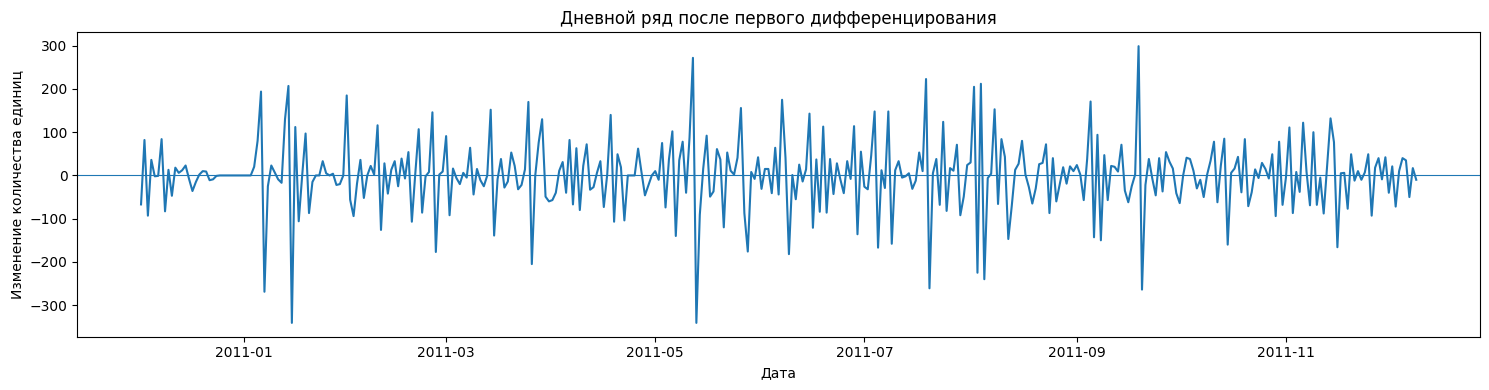

In [62]:
daily_diff = daily_series.diff().dropna()

plt.figure(figsize=(15, 4))
plt.plot(daily_diff.index, daily_diff)
plt.axhline(0, linewidth=0.8)
plt.title("Дневной ряд после первого дифференцирования")
plt.xlabel("Дата")
plt.ylabel("Изменение количества единиц")
plt.tight_layout()
plt.show()

## Пункт 4. Повторите проверку после преобразования и сравните результаты с исходным рядом.

Повторно применим ADF и KPSS к дифференцированному ряду. Сравнение p-value позволит оценить, изменились ли свидетельства в пользу стационарности.

In [63]:
stationarity_diff = check_stationarity(daily_diff, "Ряд после первого дифференцирования")

===== Ряд после первого дифференцирования =====
ADF statistic = -9.4713; p-value = 0.000000
ADF: нулевая гипотеза отвергается — есть свидетельство стационарности
KPSS statistic = 0.1154; p-value = 0.100000
KPSS: нулевая гипотеза не отвергается — результат согласуется со стационарностью


/tmp/ipykernel_50/3804296580.py:11: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf = adfuller(x, regression="c", autolag="AIC")
/tmp/ipykernel_50/3804296580.py:17: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is greater than the p-value returned.
  kpss_result = kpss(x, regression="c", nlags="auto")
/tmp/ipykernel_50/3804296580.py:17: FutureWarning: kpss currently returns a plain tuple whose length and layout depends on the store argument (and which silently drops `lags` when store=True). In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returnin

# Итоговые выводы

В ходе данной работы был произведен разведочный анализ временного ряда продаж на основе датасета Online Retail (UCI).
Для анализа был выбран товар StockCode 20725 LUNCH BAG RED RETROSPOT. Показателем продаж принято суммарное количество проданных единиц в день, неделю и месяц. Агрегация по трём частотам показала, что выбор существенно влияет на наблюдаемую структуру ряда: дневной ряд содержит больше шума и нулевых дней, недельный - сбалансирован по информативности, месячный (13 точек) отражает общую сезонность с пиком в мае 2011 года, но слишком короток для моделирования.

У данного товара были обнаружены и пропуски и выбросы, но было решено ничего с ними не делать, то тех пор пока не будет ясна конечная цель. Так как в зависимости от цели это могут быть разные обработки данных.

Была проанализированна сезонность и не было выявлено выраженного наличия или отсутствия сезонности. Также были проведены тесты на стационарность, которые не показали выраженной стационарности.